In [ ]:
# STEP 1: INSTALL AND INITIALIZE SPARK

!pip install pyspark

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("AirQuality_Spark_Performance") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Created Successfully!")

Mounted at /content/drive
Spark Version: 4.0.5
Spark Session Created Successfully!


## 2. Loading the Cleaned Air Quality Dataset

In [ ]:
# STEP 2: LOAD CLEANED PARQUET DATA

from pathlib import Path

PROJECT_DIR = Path.cwd()
PROCESSED_DIR = PROJECT_DIR / "02_Processed_Data"

station_path = PROCESSED_DIR / "station_data"

if not station_path.exists():
    raise FileNotFoundError(
        f"Cleaned monitoring station data not found: {station_path}. "
        "Run Notebook 1 first to generate the Parquet dataset."
    )

station_df = spark.read.parquet(str(station_path))

print("MONITORING STATION DATA LOADED")
print("------------------------------")
print("Total Records:", station_df.count())
print("Total Columns:", len(station_df.columns))

print("\nDATA SCHEMA")
station_df.printSchema()

print("\nSAMPLE RECORDS")
station_df.show(5, truncate=False)

MONITORING STATION DATA LOADED
------------------------------
Total Records: 15372
Total Columns: 38

DATA SCHEMA
root
 |-- date_pst: timestamp (nullable = true)
 |-- aqhi_area: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_name_full: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- cgndb: string (nullable = true)
 |-- no2_rounded: double (nullable = true)
 |-- no2_rounded_3hr: double (nullable = true)
 |-- o3_rounded: double (nullable = true)
 |-- o3_rounded_3hr: double (nullable = true)
 |-- pm25_rounded: double (nullable = true)
 |-- pm25_rounded_3hr: double (nullable = true)
 |-- so2_rounded: double (nullable = true)
 |-- so2_rounded_3hr: double (nullable = true)
 |-- active: string (nullable = true)
 |-- aqhi_pm25: string (nullable = true)
 |-- aqhi_so2: string (nullable = true)
 |-- aqhi_classic: double (nullable = true)
 |-- aqhi_plus_pm25: integer (nullable = true)
 |-- aqhi_value:

## 3. Inspecting Spark Configuration

In [ ]:


print("CURRENT SPARK CONFIGURATION")
print("---------------------------")

print(
    "Shuffle Partitions:",
    spark.conf.get("spark.sql.shuffle.partitions")
)

print(
    "Default Parallelism:",
    spark.sparkContext.defaultParallelism
)

print("\nDATASET PARTITION INFORMATION")
print("-----------------------------")

print("Number of DataFrame partitions:", station_df.rdd.getNumPartitions())

print("\nDATASET READY FOR PERFORMANCE TESTING")

CURRENT SPARK CONFIGURATION
---------------------------
Shuffle Partitions: 8
Default Parallelism: 2

DATASET PARTITION INFORMATION
-----------------------------
Number of DataFrame partitions: 1

DATASET READY FOR PERFORMANCE TESTING


## 4. Defining the Reusable Analytical Workload

To compare Spark configurations fairly, the same analytical workload is executed under both configurations.

The dataset is repartitioned into four partitions before testing. A reusable function calculates the average NO2, O3, PM2.5, and AQHI values, along with the total number of readings, for each monitoring station.

Keeping the workload consistent allows us to focus on the effect of changing the shuffle partition configuration.

In [ ]:
# STEP 4: DEFINE PERFORMANCE TEST WORKLOAD

from pyspark.sql import functions as F

# Repartition the dataset for parallel processing
performance_df = station_df.repartition(4)

print("Performance dataset partitions:",
      performance_df.rdd.getNumPartitions())

# Define the same analytical workload for both tests
def run_air_quality_analysis(df):

    result = (
        df.groupBy("station_name")
        .agg(
            F.avg("no2_rounded").alias("avg_no2"),
            F.avg("o3_rounded").alias("avg_o3"),
            F.avg("pm25_rounded").alias("avg_pm25"),
            F.avg("aqhi_value").alias("avg_aqhi"),
            F.count("*").alias("total_readings")
        )
        .orderBy("station_name")
    )

    return result

Performance dataset partitions: 4


## 5. Performance Test – Configuration A (2 Shuffle Partitions)

The first performance test uses two shuffle partitions. The analytical workload defined earlier is executed, and the elapsed execution time is recorded.

The result is collected to force Spark to execute the workload rather than simply build a lazy execution plan.

In [ ]:
# STEP 5: CONFIGURATION A - 2 SHUFFLE PARTITIONS

import time

spark.conf.set("spark.sql.shuffle.partitions", "2")

print("CONFIGURATION A")
print("----------------")
print("Shuffle Partitions:",
      spark.conf.get("spark.sql.shuffle.partitions"))

# Measure execution time
start_time = time.time()

result_A = run_air_quality_analysis(performance_df)

# Force Spark to execute the workload
result_A.collect()

end_time = time.time()

time_A = end_time - start_time

print("\nCONFIGURATION A RESULTS")
print("-----------------------")
print("Execution Time:", round(time_A, 4), "seconds")

print("\nSample Results:")
result_A.show(5, truncate=False)

CONFIGURATION A
----------------
Shuffle Partitions: 2

CONFIGURATION A RESULTS
-----------------------
Execution Time: 4.4131 seconds

Sample Results:
+---------------------------+-----------------+------------------+-----------------+------------------+--------------+
|station_name               |avg_no2          |avg_o3            |avg_pm25         |avg_aqhi          |total_readings|
+---------------------------+-----------------+------------------+-----------------+------------------+--------------+
|Castlegar Zinio Park       |4.278551136363636|10.479545454545454|9.153415300546449|1.516243169398907 |732           |
|Colwood City Hall          |4.205714285714286|12.934            |6.118331053351573|1.3325409836065574|732           |
|Courtenay Elementary School|3.758714285714287|13.45457142857143 |6.503278688524592|1.4583333333333337|732           |
|Cranbrook Muriel Baxter    |4.662910128388017|16.14308131241084 |8.845816186556927|1.7971448087431687|732           |
|Duncan College

## 6. Performance Test – Configuration B (8 Shuffle Partitions)

The second performance test uses eight shuffle partitions. It executes the same analytical workload used in Configuration A so that the two configurations can be compared under consistent conditions.

In [ ]:
# STEP 6: CONFIGURATION B - 8 SHUFFLE PARTITIONS

spark.conf.set("spark.sql.shuffle.partitions", "8")

print("CONFIGURATION B")
print("----------------")
print("Shuffle Partitions:",
      spark.conf.get("spark.sql.shuffle.partitions"))

# Measure execution time
start_time = time.time()

result_B = run_air_quality_analysis(performance_df)

# Force Spark to execute the workload
result_B.collect()

end_time = time.time()

time_B = end_time - start_time

print("\nCONFIGURATION B RESULTS")
print("-----------------------")
print("Execution Time:", round(time_B, 4), "seconds")

print("\nSample Results:")
result_B.show(5, truncate=False)

CONFIGURATION B
----------------
Shuffle Partitions: 8

CONFIGURATION B RESULTS
-----------------------
Execution Time: 1.2405 seconds

Sample Results:
+---------------------------+-----------------+------------------+-----------------+------------------+--------------+
|station_name               |avg_no2          |avg_o3            |avg_pm25         |avg_aqhi          |total_readings|
+---------------------------+-----------------+------------------+-----------------+------------------+--------------+
|Castlegar Zinio Park       |4.278551136363636|10.479545454545454|9.153415300546449|1.516243169398907 |732           |
|Colwood City Hall          |4.205714285714286|12.934            |6.118331053351573|1.3325409836065574|732           |
|Courtenay Elementary School|3.758714285714287|13.45457142857143 |6.503278688524592|1.4583333333333337|732           |
|Cranbrook Muriel Baxter    |4.662910128388017|16.14308131241084 |8.845816186556927|1.7971448087431687|732           |
|Duncan College

## 7. Repeated Performance Benchmark

To improve the reliability of the performance comparison, each Spark configuration is tested three times after an initial warm-up run.

The warm-up runs are excluded from the measurements. The average and median execution times are calculated for both configurations to reduce the influence of individual timing variations.

In [ ]:

import time
import statistics

times_A = []
times_B = []

# Warm-up runs (not included in final measurements)
spark.conf.set("spark.sql.shuffle.partitions", "2")
run_air_quality_analysis(performance_df).collect()

spark.conf.set("spark.sql.shuffle.partitions", "8")
run_air_quality_analysis(performance_df).collect()

# Three measured runs for each configuration
for i in range(3):

    # Configuration A
    spark.conf.set("spark.sql.shuffle.partitions", "2")

    start = time.perf_counter()
    run_air_quality_analysis(performance_df).collect()
    times_A.append(time.perf_counter() - start)

    # Configuration B
    spark.conf.set("spark.sql.shuffle.partitions", "8")

    start = time.perf_counter()
    run_air_quality_analysis(performance_df).collect()
    times_B.append(time.perf_counter() - start)

print("REPEATED BENCHMARK RESULTS")
print("--------------------------")

print("\nConfiguration A (2 partitions):")
print("Run times:", [round(t, 4) for t in times_A])
print("Average:", round(statistics.mean(times_A), 4), "seconds")
print("Median:", round(statistics.median(times_A), 4), "seconds")

print("\nConfiguration B (8 partitions):")
print("Run times:", [round(t, 4) for t in times_B])
print("Average:", round(statistics.mean(times_B), 4), "seconds")
print("Median:", round(statistics.median(times_B), 4), "seconds")

REPEATED BENCHMARK RESULTS
--------------------------

Configuration A (2 partitions):
Run times: [0.9868, 0.803, 0.6833]
Average: 0.8244 seconds
Median: 0.803 seconds

Configuration B (8 partitions):
Run times: [0.7896, 0.8139, 1.1936]
Average: 0.9323 seconds
Median: 0.8139 seconds


## 8. Comparing Spark Performance Results

,Configuration,Average Time (seconds),Median Time (seconds)
0,Configuration A (2 partitions),0.8244,0.8030
1,Configuration B (8 partitions),0.9323,0.8139


Configuration A was 11.58% faster on average.


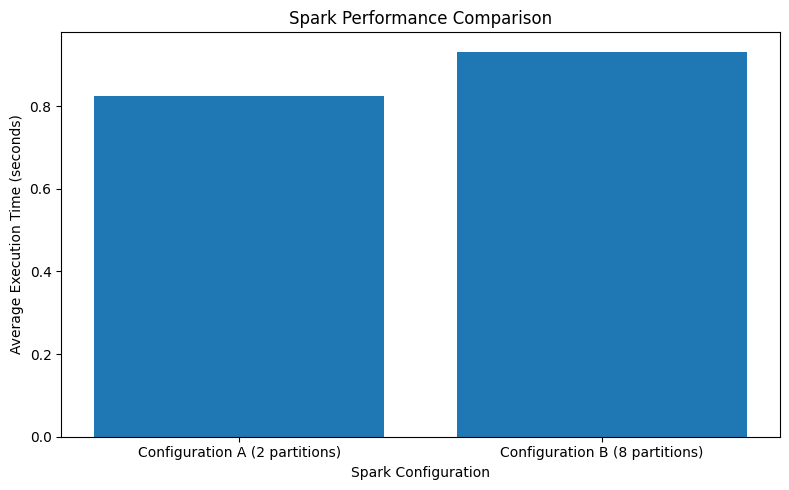

In [ ]:
# FINAL SPARK PERFORMANCE COMPARISON

import pandas as pd
import matplotlib.pyplot as plt
import statistics
from pathlib import Path

# Create comparison table
comparison_df = pd.DataFrame({
    "Configuration": [
        "Configuration A (2 partitions)",
        "Configuration B (8 partitions)"
    ],
    "Average Time (seconds)": [
        statistics.mean(times_A),
        statistics.mean(times_B)
    ],
    "Median Time (seconds)": [
        statistics.median(times_A),
        statistics.median(times_B)
    ]
})

print("FINAL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

# Calculate percentage difference
average_A = statistics.mean(times_A)
average_B = statistics.mean(times_B)

if average_A > 0 and average_B > 0:
    difference = ((average_B - average_A) / average_B) * 100

    if difference > 0:
        print(f"\nConfiguration A was {difference:.2f}% faster on average.")
    elif difference < 0:
        print(f"\nConfiguration B was {abs(difference):.2f}% faster on average.")
    else:
        print("\nBoth configurations had the same average execution time.")

# Generate comparison graph
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Configuration"],
    comparison_df["Average Time (seconds)"]
)

plt.title("Spark Performance Comparison")
plt.xlabel("Spark Configuration")
plt.ylabel("Average Execution Time (seconds)")
plt.tight_layout()

# Save visualization in the project folder
PROJECT_DIR = Path.cwd()
PLOTS_DIR = PROJECT_DIR / "04_Visualizations"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

plot_path = PLOTS_DIR / "Spark_Performance_Comparison.png"

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPerformance graph saved to:", plot_path)

## 9. Performance Experiment Conclusion

This experiment compared Apache Spark execution performance using two shuffle partition configurations: 2 partitions and 8 partitions.

Both configurations executed the same air quality aggregation workload using the cleaned monitoring station dataset. Each configuration was tested three times after an initial warm-up run. Average and median execution times were used to compare performance.

The results demonstrate that the number of shuffle partitions can influence Spark execution time. Increasing the number of partitions does not necessarily improve performance, particularly when working with a relatively small dataset.

The faster configuration in this experiment is determined by comparing the measured average execution times. These findings are specific to the dataset, workload, and computing environment used in this experiment. Additional testing with larger datasets and different partition configurations would provide a broader understanding of Spark performance.